# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 **without ImageNet pretraining and without tuning** (`NO_TUNING_ARCH_HYPERPARAMS["resnet18"]`), then saves its results and weights to disk for the results notebook. This is the baseline role AlexNet used to play — see `wwtw_utils.py`'s `ARCH_HYPERPARAMS` comment for why the baseline is now the *same* architecture as the tuned, pretrained `resnet18` run rather than a different one.


In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): Waterval
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']
Train: 1803 | Val: 440 | Test: 284


## Build dataloaders + class weights for this architecture

In [2]:
cfg = NO_TUNING_ARCH_HYPERPARAMS["resnet18"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders, same as every other architecture
# here -- its own (capped) batch size and image size, per cfg.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 32)


## Define the model (ResNet-18, trained from scratch)

In [3]:
# ---------------------------------------------------------
# Define the CNN (ResNet-18, trained from scratch — no ImageNet weights)
# ---------------------------------------------------------
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the tuned step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ResNet-18 (scratch)] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[ResNet-18 (scratch)] Epoch   1/100 | LR: 1.00e-04 | train loss 1.0867 acc 0.466 | val loss 1.0246 acc 0.545 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 1.00e-04 | train loss 1.0166 acc 0.521 | val loss 0.8898 acc 0.598 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 1.00e-04 | train loss 0.9147 acc 0.562 | val loss 0.9354 acc 0.584


[ResNet-18 (scratch)] Epoch   4/100 | LR: 1.00e-04 | train loss 0.9382 acc 0.555 | val loss 0.8104 acc 0.666 *


...

[ResNet-18 (scratch)] Epoch  26/100 | LR: 1.00e-05 | train loss 0.4282 acc 0.809 | val loss 0.4971 acc 0.802


[ResNet-18 (scratch)] Epoch  27/100 | LR: 1.00e-05 | train loss 0.3982 acc 0.803 | val loss 0.4717 acc 0.825


[ResNet-18 (scratch)] Epoch  28/100 | LR: 1.00e-05 | train loss 0.3937 acc 0.813 | val loss 0.4733 acc 0.832


[ResNet-18 (scratch)] Epoch  29/100 | LR: 1.00e-05 | train loss 0.4049 acc 0.806 | val loss 0.4796 acc 0.830


[ResNet-18 (scratch)] Epoch  30/100 | LR: 1.00e-06 | train loss 0.3854 acc 0.819 | val loss 0.4685 acc 0.820

[ResNet-18 (scratch)] No val loss improvement for 10 epochs — stopping early at epoch 30.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.4637)


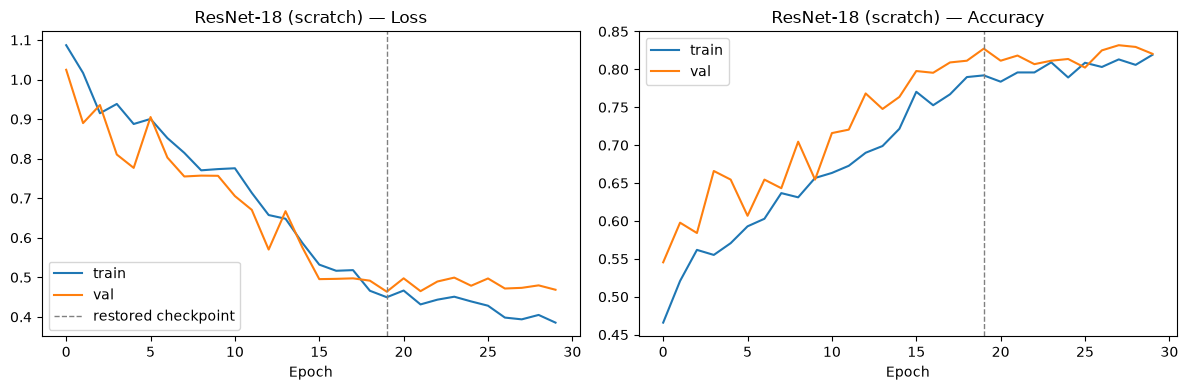

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.785


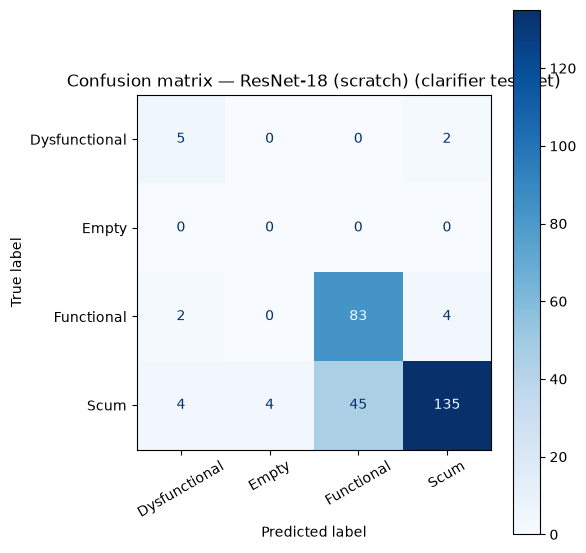

               precision    recall  f1-score   support

Dysfunctional      0.455     0.714     0.556         7
        Empty      0.000     0.000     0.000         0
   Functional      0.648     0.933     0.765        89
         Scum      0.957     0.718     0.821       188

     accuracy                          0.785       284
    macro avg      0.515     0.591     0.535       284
 weighted avg      0.848     0.785     0.797       284

  [warn] 'Empty' has 0 examples in this test set — AUC undefined, skipping.


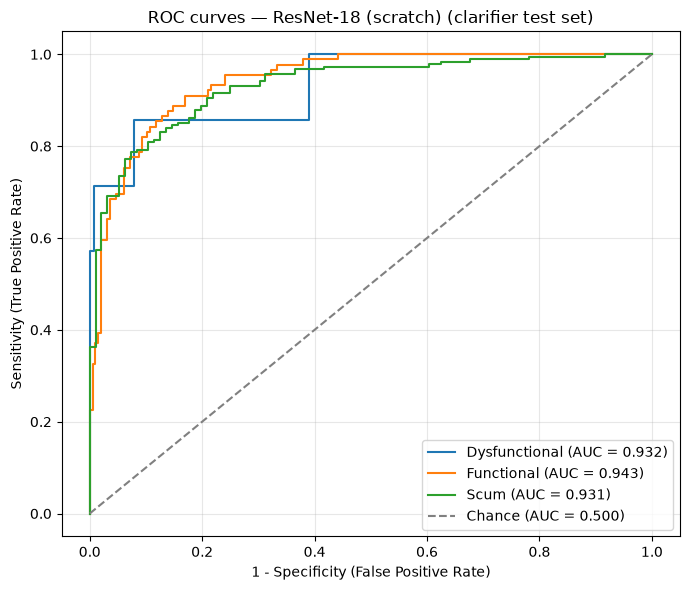

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.932
  Empty          : undefined (0 examples)
  Functional     : 0.943
  Scum           : 0.931

Mean AUC (over 3/4 classes with test examples): 0.935


(np.float64(0.7852112676056338),
 {'Dysfunctional': 0.9319236719958741,
  'Empty': nan,
  'Functional': 0.9428983002016711,
  'Scum': 0.9314051418439717})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

This is the step the results notebook depends on — it pickles the metrics/history and saves the model state dict so nothing needs to be kept in memory or re-trained.

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/clarifier_aug/results_clarifier_resnet18_scratch_Waterval.pkl


Saved model weights to ../models/pad/clarifier_resnet18_scratch_cnn.pt
